# KNN simples: o estagiário será contratado?
Vamos prever um rótulo usando dois números: **frequência** e **desenrolo**. O algoritmo usa apenas listas, dicionários, funções e operações do Python. Matplotlib será usado somente para os gráficos.

Os dados são **fictícios**, criados para esta aula. `contratado` é o rótulo conhecido dos exemplos. A previsão do novo estagiário corresponde à votação dos vizinhos.

## Antes de começar
1. Baixe `estagiarios.csv` e coloque-o na mesma pasta deste notebook. No Colab, envie o CSV na aba **Arquivos**.
2. Execute as células em ordem. Se precisar instalar o Matplotlib, use `python -m pip install matplotlib` no terminal ou `%pip install matplotlib` em uma célula do notebook.

### As três colunas
| Coluna | Significado |
|---|---|
| `frequencia` | Presença em relação ao total de dias, de 0 a 100% |
| `desenrolo` | Nota fictícia de comunicação e autonomia, expressa de 0 a 100% para o exercício |
| `contratado` | Resposta já conhecida: `sim` ou `nao` |

As duas características usam a mesma escala de 0 a 100. Neste primeiro exemplo, a distância atribui o mesmo peso a um ponto percentual em cada característica.

In [1]:
import csv
import math
import matplotlib.pyplot as plt

## 1. Ler o CSV
`csv.DictReader` transforma cada linha em um dicionário. Como os valores chegam como texto, convertemos frequência e desenrolo com `float`. O arquivo contém números como `85`, sem o sinal `%`.

In [2]:
def ler_estagiarios(nome_arquivo):
    estagiarios = []
    with open(nome_arquivo, encoding="utf-8", newline="") as arquivo:
        leitor = csv.DictReader(arquivo)
        for linha in leitor:
            estagiario = {
                "frequencia": float(linha["frequencia"]),
                "desenrolo": float(linha["desenrolo"]),
                "contratado": linha["contratado"],
            }
            estagiarios.append(estagiario)
    return estagiarios

estagiarios = ler_estagiarios("estagiarios.csv")
print("Quantidade de exemplos:", len(estagiarios))
for estagiario in estagiarios[:5]:
    print(estagiario)

Quantidade de exemplos: 17
{'frequencia': 40.0, 'desenrolo': 30.0, 'contratado': 'nao'}
{'frequencia': 55.0, 'desenrolo': 40.0, 'contratado': 'nao'}
{'frequencia': 60.0, 'desenrolo': 65.0, 'contratado': 'nao'}
{'frequencia': 70.0, 'desenrolo': 45.0, 'contratado': 'nao'}
{'frequencia': 75.0, 'desenrolo': 60.0, 'contratado': 'nao'}


## 2. Medir a distância entre dois estagiários
Cada estagiário é um ponto `(frequencia, desenrolo)`.

Usamos a distância euclidiana:
$$d = \sqrt{(f_1-f_2)^2 + (d_1-d_2)^2}$$

Para comparar `(85,75)` com `(88,76)`:
$$\sqrt{(85-88)^2 + (75-76)^2}=\sqrt{9+1}=\sqrt{10}\approx3{,}16.$$

Quanto menor a distância, mais próximos os dois pontos. Essa distância é geométrica e não é uma porcentagem de chance de contratação.

In [3]:
def distancia_euclidiana(estagiario1, estagiario2):
    diferenca_frequencia = estagiario1["frequencia"] - estagiario2["frequencia"]
    diferenca_desenrolo = estagiario1["desenrolo"] - estagiario2["desenrolo"]
    distancia = math.sqrt(diferenca_frequencia ** 2 + diferenca_desenrolo ** 2)
    return distancia

exemplo1 = {"frequencia": 85, "desenrolo": 75}
exemplo2 = {"frequencia": 88, "desenrolo": 76}
print("Distância:", round(distancia_euclidiana(exemplo1, exemplo2), 2))

Distância: 3.16


## 3. Construir o KNN
K é a quantidade de vizinhos que votam. Com **K = 3**, usamos os três exemplos mais próximos.

1. Percorrer os exemplos conhecidos e calcular suas distâncias ao novo ponto.
2. Guardar pares `(distancia, estagiario)` em uma lista.
3. Ordenar a lista pela distância.
4. Selecionar os K primeiros com `distancias[:k]`.
5. Contar as respostas `sim` e `nao`.

Em `key=lambda item: item[0]`, estamos dizendo: **use o primeiro elemento do par, a distância, para ordenar**. Para empates de distância, o Python mantém a ordem original do CSV. Neste exercício, um empate na votação resulta em `nao`. Com duas classes e K ímpar, não há empate de votos.

In [4]:
def knn(estagiarios, novo_estagiario, k=3):
    if k < 1 or k > len(estagiarios):
        raise ValueError("K deve estar entre 1 e a quantidade de estagiários.")

    distancias = []
    for estagiario in estagiarios:
        distancia = distancia_euclidiana(estagiario, novo_estagiario)
        distancias.append((distancia, estagiario))

    # item[0] é a distância. Ordenamos do menor para o maior.
    distancias.sort(key=lambda item: item[0])
    vizinhos = distancias[:k]

    votos_sim = 0
    votos_nao = 0
    for distancia, estagiario in vizinhos:
        if estagiario["contratado"] == "sim":
            votos_sim += 1
        else:
            votos_nao += 1

    if votos_sim > votos_nao:
        previsao = "sim"
    else:
        previsao = "nao"  # Regra deste exemplo para eventual empate.
    return previsao, vizinhos

## 4. Fazer a previsão
O novo estagiário não possui o campo `contratado`. Essa é a resposta que queremos inferir a partir dos exemplos.

**Antes de executar:** com 85% de frequência e 75% de desenrolo, qual resposta você espera?

In [5]:
novo_estagiario = {"frequencia": 85, "desenrolo": 75}
k = 3

previsao, vizinhos = knn(estagiarios, novo_estagiario, k)
print("Previsão de contratação:", previsao)
print("Vizinhos mais próximos:")
for distancia, estagiario in vizinhos:
    print(estagiario, "Distância:", round(distancia, 2))

Previsão de contratação: sim
Vizinhos mais próximos:
{'frequencia': 88.0, 'desenrolo': 76.0, 'contratado': 'sim'} Distância: 3.16
{'frequencia': 83.0, 'desenrolo': 78.0, 'contratado': 'sim'} Distância: 3.61
{'frequencia': 82.0, 'desenrolo': 72.0, 'contratado': 'nao'} Distância: 4.24


### Interpretar a votação
Para esses valores, os vizinhos são:

| Frequência | Desenrolo | Contratado | Distância aproximada |
|---|---|---|---|
| 88% | 76% | sim | 3,16 |
| 83% | 78% | sim | 3,61 |
| 82% | 72% | nao | 4,24 |

**Dois votos `sim` e um voto `nao`: previsão `sim`.** A votação não representa uma probabilidade calibrada.

O KNN não ajustou pesos nem uma reta. Neste exemplo, ele guardou os casos conhecidos, mediu as distâncias e consultou os vizinhos.

## 5. Mostrar o novo estagiário no gráfico
- Eixo horizontal: frequência.
- Eixo vertical: desenrolo.
- Verde: exemplos com `contratado = sim`.
- Laranja: exemplos com `contratado = nao`.
- Estrela amarela: o novo estagiário.
- Círculos e linhas tracejadas: os vizinhos que participaram da votação.

A função abaixo cuida apenas da visualização. Ela não interfere na previsão calculada pelo KNN.

In [6]:
def mostrar_grafico(estagiarios, novo_estagiario, vizinhos, ampliar=False):
    fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
    cores = {"sim": "#178273", "nao": "#D66A54"}

    for estagiario in estagiarios:
        ax.scatter(estagiario["frequencia"], estagiario["desenrolo"],
                   color=cores[estagiario["contratado"]], s=90,
                   edgecolor="white", linewidth=0.8, zorder=3)

    for indice, (distancia, estagiario) in enumerate(vizinhos, start=1):
        ax.plot([novo_estagiario["frequencia"], estagiario["frequencia"]],
                [novo_estagiario["desenrolo"], estagiario["desenrolo"]],
                color="#81929E", linestyle="--", linewidth=1.3, zorder=2)
        ax.scatter(estagiario["frequencia"], estagiario["desenrolo"],
                   s=230, facecolors="none", edgecolors="#21374C",
                   linewidth=1.5, zorder=4)
        if ampliar:
            ax.annotate(f"{indice}º: {distancia:.2f}",
                        (estagiario["frequencia"], estagiario["desenrolo"]),
                        xytext=(12, 12), textcoords="offset points",
                        fontsize=11, color="#21374C")

    ax.scatter(novo_estagiario["frequencia"], novo_estagiario["desenrolo"],
               marker="*", s=380, color="#F2BE45", edgecolor="#21374C",
               linewidth=1.2, zorder=5, label="Novo estagiário")
    ax.scatter([], [], color=cores["sim"], s=90, label="Contratado: sim")
    ax.scatter([], [], color=cores["nao"], s=90, label="Contratado: não")

    if ampliar:
        frequencias = [novo_estagiario["frequencia"]] + [e["frequencia"] for d, e in vizinhos]
        desenrolos = [novo_estagiario["desenrolo"]] + [e["desenrolo"] for d, e in vizinhos]
        ax.set_xlim(max(0, min(frequencias) - 5), min(100, max(frequencias) + 6))
        ax.set_ylim(max(0, min(desenrolos) - 5), min(100, max(desenrolos) + 6))
    else:
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Frequência (%)", fontsize=13)
    ax.set_ylabel("Desenrolo (%)", fontsize=13)
    ax.set_title("KNN: novo estagiário e seus vizinhos", fontsize=16, pad=15)
    ax.legend(loc="upper left", fontsize=10, framealpha=0.95)
    ax.grid(color="#E3E9EE", linewidth=0.7, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    return fig

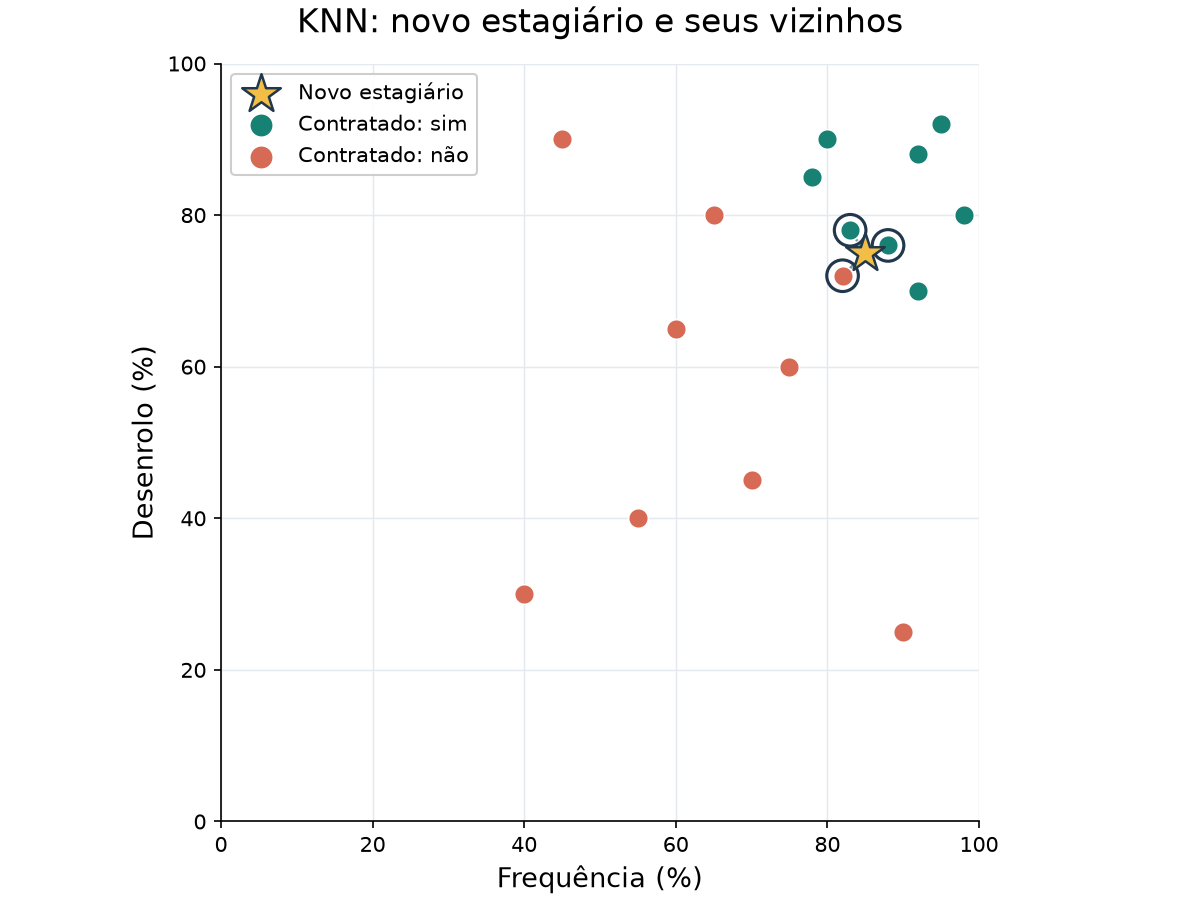

In [7]:
fig = mostrar_grafico(estagiarios, novo_estagiario, vizinhos)
plt.show()

### Ampliar para enxergar os três vizinhos
O gráfico a seguir usa o mesmo resultado, aproximando a região ao redor do novo ponto. Os números nas anotações são as distâncias calculadas pela nossa função.

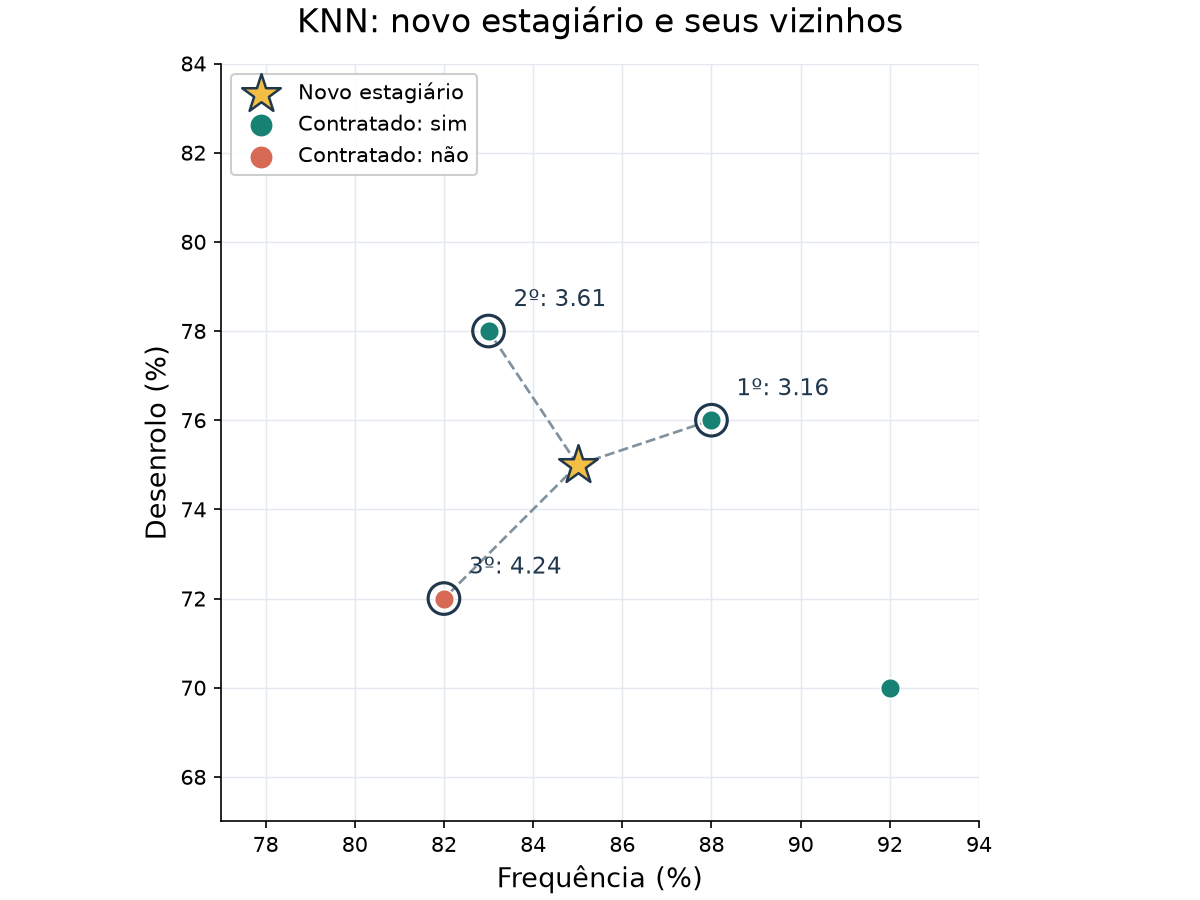

In [8]:
fig = mostrar_grafico(estagiarios, novo_estagiario, vizinhos, ampliar=True)
plt.show()

## 6. Exercício dos alunos
1. Troque o novo ponto para frequência `60` e desenrolo `50`. Faça uma previsão antes de executar.
2. Volte para `(85,75)` e compare K igual a 1, 3 e 5. Conte os votos.
3. Acrescente uma linha ao CSV, leia o arquivo novamente e observe se os vizinhos mudam.
4. Aumente apenas a frequência, mantendo o desenrolo fixo. O resultado necessariamente muda?
5. Troque a distância euclidiana por Manhattan: soma dos valores absolutos das diferenças. Compare os vizinhos.

Para cada experimento, informe a previsão, os vizinhos, suas distâncias e a votação. Estes poucos dados demonstram o funcionamento do algoritmo. Para medir desempenho em casos novos, uma etapa posterior deve separar exemplos de treino e teste.

Nova previsão: nao
{'frequencia': 55.0, 'desenrolo': 40.0, 'contratado': 'nao'} Distância: 11.18
{'frequencia': 70.0, 'desenrolo': 45.0, 'contratado': 'nao'} Distância: 11.18
{'frequencia': 60.0, 'desenrolo': 65.0, 'contratado': 'nao'} Distância: 15.0


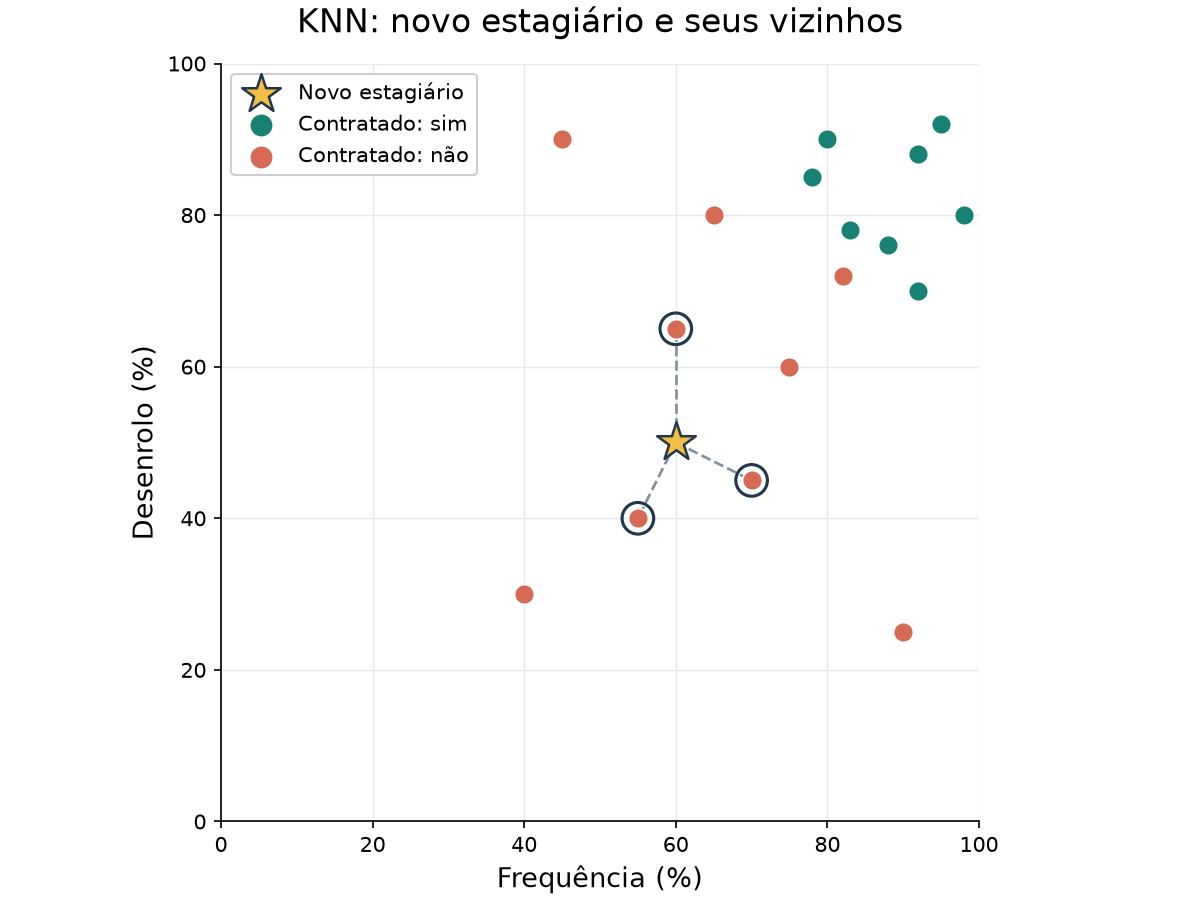

In [9]:
novo_estagiario = {"frequencia": 60, "desenrolo": 50}  # ALTERE AQUI
k = 3
previsao, vizinhos = knn(estagiarios, novo_estagiario, k)
print("Nova previsão:", previsao)
for distancia, estagiario in vizinhos:
    print(estagiario, "Distância:", round(distancia, 2))
fig = mostrar_grafico(estagiarios, novo_estagiario, vizinhos)
plt.show()

## 7. Limitações do Modelo Knn
• Alto custo computacional na predição: Como é um algoritmo "preguiçoso" (lazy learner), ele não constrói um modelo durante o treinamento; em vez disso, precisa calcular a distância entre o ponto de teste e todos os exemplos da base de dados em tempo de execução.

• Alto consumo de memória e armazenamento: O modelo exige que toda a base de dados de treinamento fique armazenada na memória RAM para realizar as consultas.

• Maldição da dimensionalidade: O desempenho cai drasticamente quando o número de características (dimensões) é muito alto, pois o espaço torna-se esparso e as distâncias entre os pontos perdem o significado.

• Sensibilidade à escala dos dados: Variáveis com ordens de grandeza muito diferentes (ex: salário em milhares vs. idade de 0 a 100) distorcem o cálculo da distância, exigindo sempre normalização ou padronização prévia.

• Dificuldade na escolha do hiperparâmetro k: Um valor de k muito baixo torna o modelo sensível a ruídos e outliers (risco de overfitting), enquanto um k muito alto pode suavizar excessivamente as fronteiras e gerar underfitting.

• Desempenho ruim com dados desequilibrados: Classes majoritárias tendem a dominar a votação ou a média de vizinhos, prejudicando a identificação de classes minoritárias.